<a href="https://colab.research.google.com/github/josafatdzec-crypt/everpeak-analysis/blob/main/S5_Proyecto_1_movilidad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Datos reales de TomTom Traffic Index y OECD Cities. Identificar en qué ciudades conviene invertir en infraestructura de transporte.

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.


In [ ]:
# importarlibrerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [ ]:
# mostrar las primeras 5 filas de traffic
traffic.head(5)

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
# mostrar las primeras 5 filas de eco
eco.head(5)

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


### Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.


In [ ]:
# Examinar la estructura de traffic
traffic.info(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

Columnas `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` son de tipo object
- Cambiar el dato a númerico y/o cambiar decimales o carácteres especiales para tatrar los datos y probablementle el nombre de las columnas para identificar mejor los datos

In [ ]:
# Examinar la estructura de eco
eco.info(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, `PM2.5 (μg/m³)`, `Population (M)`
- Cambiar datos de estas columnas a números y/o elimnar decimiales o caratcteres extras

### Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

- Cambiar los nombres de las columnas para que tengan el formato `snake_case`.

- Verifica que los cambios

In [ ]:
# Estandarizar los nombres de las columnas de traffic
traffic.columns = [
    'country', 'city', 'update_time_utc', 'jams_delay', 'traffic_index_live',
    'jams_length_kms', 'jams_count', 'traffic_index_week_ago',
    'update_time_utc_week_ago', 'travel_time_live_per_10kms_mins',
    'travel_time_hist_per_10kms_mins', 'mins_delay'
]
# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins',
       'mins_delay'],
      dtype='object')

In [ ]:
# Estandarizar los nombres de las columnas de eco
eco.columns = ['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
    'pm25', 'population_m']#tu código aquí

# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')

###Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

- Columnas de fecha de `traffic` a formato `datetime`.
- En el dataset `eco`, limpiar los valores numéricos:
    - En `city_gdp_capita`: eliminar separadores y reemplazar las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: eliminar el símbolo de porcentaje (`%`) y reemplazar las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplazar las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, se creo una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()

traffic['update_time_utc'] = pd.to_datetime(traffic["update_time_utc"], errors="coerce") #tu código aquí
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'],errors="coerce")#tu código aquí


# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   country                          1004464 non-null  object        
 1   city                             1004464 non-null  object        
 2   update_time_utc                  1004464 non-null  datetime64[ns]
 3   jams_delay                       1004464 non-null  float64       
 4   traffic_index_live               1004464 non-null  float64       
 5   jams_length_kms                  1004464 non-null  float64       
 6   jams_count                       1004464 non-null  float64       
 7   traffic_index_week_ago           1004464 non-null  float64       
 8   update_time_utc_week_ago         1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins  1004464 non-null  float64       
 10  travel_time_hist_per_10kms_min

In [ ]:
# Recargar para limpiar
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

# Renombrar
eco.columns = ['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct', 'pm25', 'population_m']

# Limpiar numéricas en eco
eco['city_gdp_capita'] = eco["city_gdp_capita"].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)
eco['unemployment_pct'] = eco["unemployment_pct"].astype(str).str.replace("%", "", regex=False).str.replace(",", ".").astype(float)
eco['population_m'] = eco["population_m"].astype(str).str.replace(",", ".", regex=False).astype(float)

# Calcular la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = eco["population_m"] * 1000000

# Verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0



---

## Extraer año y filtrar

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

- Como el DataFrame `traffic` no tiene una columna de año, crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [ ]:
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar los cambios
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()


display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0



---

##Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. Calcular los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

###Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

- Agrupar los datos por `city`, `country` y `year`.
- Calcular el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Resultado guardado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


In [ ]:
# Calcular los  promedios de trafico por ciudad, país y año
traffic_city_year_2024 = traffic_2024.groupby(["city","country","year"])[['jams_delay', 'traffic_index_live', 'jams_length_kms',
         'jams_count', 'travel_time_live_per_10kms_mins', 'mins_delay','travel_time_hist_per_10kms_mins']].mean().reset_index()


# Mostrar resultado
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,travel_time_live_per_10kms_mins,mins_delay,travel_time_hist_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,16.267977,0.774172,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,13.397861,0.792968,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,15.219292,0.495276,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,9.829092,0.139764,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,15.879694,1.129749,14.749945


In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)# tu código aquí

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,travel_time_live_per_10kms_mins,mins_delay,travel_time_hist_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,21.809092,1.855542,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,22.443778,0.698152,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,18.505043,1.396351,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,17.714139,1.325160,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,27.134629,2.469894,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,16.226009,0.633294,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,15.746717,0.501802,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,11.662590,0.194951,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,9.467150,-0.017544,9.484694



---

## Unir movilidad y economía

Combinar datasets que permita analizar cómo se relacionan los indicadores económicos con los de movilidad.

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

- Usar `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Unir ambos DataFrames y definir como **claves de unión** a `city` y `year`.
- Mantener solo las ciudades y años presentes en ambos datasets.
- Guardar el resultado en una nueva variable `merged`


In [ ]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = traffic_2024_small.merge(eco_2024_small, on= ['city','year'], how="inner")# tu código aquí

merged.head(10) # Mostrar las primeras 5 filas
# tu código aquí

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3700000.0
5,fortaleza,BRA,2024,82.813181,15.896749,11.205844,24.644991,0.081618,19.267171,19.185554,8512.0,11.8,"14,60",4200000.0
6,lima,PER,2024,1052.292789,31.031277,110.314770,213.453519,1.506305,25.674261,24.167956,13472.0,6.5,"19,70",11200000.0
7,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550,21111.0,3.2,"22,30",22100000.0
8,montevideo,URY,2024,50.201092,17.014854,6.369201,14.160332,0.393442,18.892342,18.498900,26176.0,8.4,"11,20",1800000.0
9,porto-alegre,BRA,2024,139.382830,17.687254,20.167849,39.813403,0.194195,16.166684,15.972490,11801.0,8.7,"14,20",4300000.0



---
##Visualización y análisis de relaciones

###Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

- Usar `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualizar la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** (media, mediana y detectar valores atípicos)
- Visualizar la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **comparar ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.


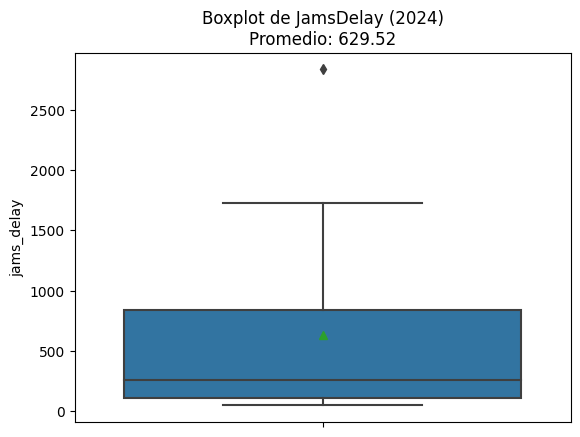

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,montevideo,URY,2024,50.201092,17.014854,6.369201,14.160332,0.393442,18.892342,18.498900,261760.0,8.4,"11,20",1800000.0
1,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550,211110.0,3.2,"22,30",22100000.0
2,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,181170.0,7.2,"14,50",15400000.0
3,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,162510.0,7.8,"12,80",4800000.0
4,sao-paulo,BRA,2024,1729.189270,26.877932,238.419896,431.470460,1.129026,20.801836,19.672810,147030.0,8.5,"28,00",22600000.0
5,lima,PER,2024,1052.292789,31.031277,110.314770,213.453519,1.506305,25.674261,24.167956,134720.0,6.5,"19,70",11200000.0
6,rio-de-janeiro,BRA,2024,466.064706,25.162963,85.015120,123.891939,0.361302,17.137320,16.776018,133490.0,9.2,"18,40",13700000.0
7,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,123810.0,8.2,"13,50",3700000.0
8,porto-alegre,BRA,2024,139.382830,17.687254,20.167849,39.813403,0.194195,16.166684,15.972490,118010.0,8.7,"14,20",4300000.0
9,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,114420.0,10.0,"17,60",11300000.0


In [ ]:
sns.boxplot(data = merged, y='jams_delay',showmeans=True, order = merged ['city_gdp_capita'].value_counts().index)# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
# crea tu gráfico

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()

# 3. Mostrar la tabla ya ordenada correctamente
display(merged)

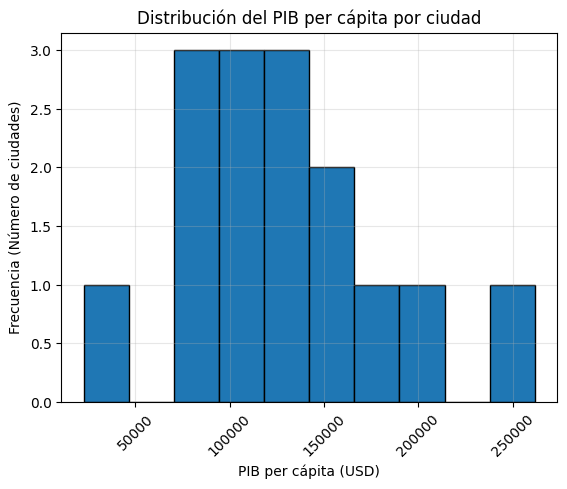

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
merged['city_gdp_capita'].hist(bins=10, edgecolor='black')

plt.title('distribución del PIB per cápita por ciudad')
plt.xlabel('PIB per cápita (USD)')
plt.ylabel('Frecuencia (Número de ciudades)')
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.show()

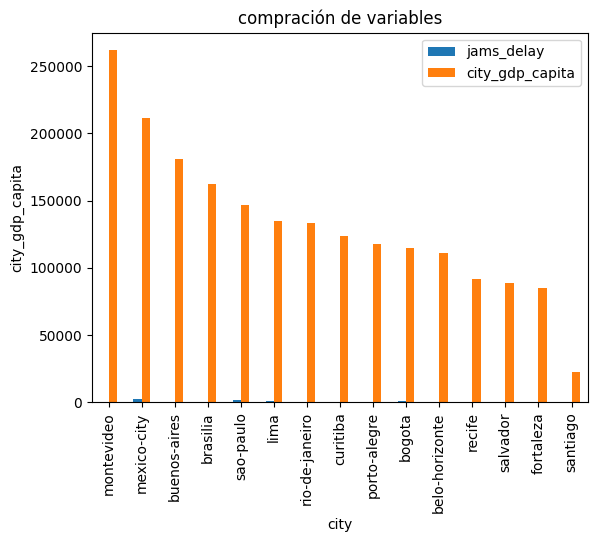

In [ ]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
merged.plot(kind='bar', x='city', y=['jams_delay', 'city_gdp_capita'])
plt.xticks(rotation=90)
plt.title('compración de variables')
plt.xlabel('city')
plt.ylabel('city_gdp_capita')
plt.show()


---

## Exportar y documentar resultados

Guardar el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

- Exportar el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

En los datos analizados de los países registrados del año 2024 no tiene relación la congestión y tiempos de viaje con el PIB per cápita, en realidad la relación se encuentra en la cantidad de población con la congestión y tiempos de viaje, países como México y Brasil que tiene poblaciones mayores también tienen mayores tiempos de congestión y tiempos de viajes, entre las variables registradas podemos encontrar que los niveles de pm25 son mayores en las ciudades que tienen tiempos de congestión altos, pudiendo concluir que el número de población, jams_count y el nivel de pm25 estan altamente relacionados, la relación lógica si aumenta la población, aumenta las variables de jams count y pm25
Cobertura de Datos: se obtuvo el años 2024 y se evaluaron los países latinoamericanos

Describe los procesos principales:
- Se cargaron los datos atraves de import y la dirección de los archivos junto a head e info, pude observar que datos y que tipo de datos
- Inicie la limpieza de ambos dataset reemplazando puntos y comas por guiones bajos para tener la misma estructura de snake_case, se multiplico la población para tener la cantidad entera
- Como el año de interes era 2024 se filtro el año pero antes usamos el atributo dt.year para extraer y generar una nueva columna como año
- Se crearon nuevos dataframes con copy para resguaradar los datos originales, y se unieron con las columnas de ciudad y año, permitiendo observar los datos
- Personalmente busco ordenar por PIB para obervar mas clara la relación con la ocngestión y tiempos de traslado de cada ciudad
  
En particular la ciudad de Montevideo tiene mayor PIB y menor congestionamiento registrado, esta relación es contraria a ciudad de México que tiene el segundo PIB mayor pero la congestión en primer lugar, las ciudades como Lima y Bogota tiene valores cercanos en su delay count y su población sin embargo Lima tiene mayor PIB y menor delay count, mientras que Bogota tiene menor PIB y mayor delay count, podemos concluir que Uruguay invierte su PIB que es el mas alto en 2024 probalemente invertido en infraestructura o acciones que hacen menor el delay count, insistiendo que una varibale importante es la población y probablemente en la densidad poblacional que podriamos agregar